In [26]:
%pip install librosa matplotlib numpy 
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder


# Load the data
dataset = pd.read_csv('dataset.csv')

# Check the first few rows of the dataset
print("Dataset (first 5 rows):")
print(dataset.head())

# Encode categorical columns using LabelEncoder
categorical_columns = dataset.select_dtypes(include=['object']).columns
label_encoders = {}
for column in categorical_columns:
    le = LabelEncoder()
    dataset[column] = le.fit_transform(dataset[column].astype(str))
    label_encoders[column] = le  # Store encoder for future use

# Check for missing values
print("\nMissing values in dataset:")
print(dataset.isnull().sum())

# Fill missing values in numeric columns with the mean
numeric_columns = dataset.select_dtypes(include=['int64', 'float64']).columns
dataset[numeric_columns] = dataset[numeric_columns].fillna(dataset[numeric_columns].mean())

# Split the data into train and test sets (80% train, 20% test)
train_data, test_data = train_test_split(dataset, test_size=0.2, random_state=42)

# Apply the same encoding to test data using the same encoders
for column in categorical_columns:
    if column in test_data.columns:
        test_data[column] = test_data[column].astype(str)
        # Handle unseen labels in test data by mapping to a default value
        test_data[column] = test_data[column].map(lambda s: s if s in label_encoders[column].classes_ else label_encoders[column].classes_[0])
        test_data[column] = label_encoders[column].transform(test_data[column])

# Fill missing values in test data numeric columns with the mean (from train data)
test_data[numeric_columns] = test_data[numeric_columns].fillna(train_data[numeric_columns].mean())

# Check the train and test datasets
print("\nTrain dataset (first 5 rows):")
print(train_data.head())
print("\nTest dataset (first 5 rows):")
print(test_data.head())

# Verify missing values have been handled
print("\nMissing values in train dataset:")
print(train_data.isnull().sum())
print("\nMissing values in test dataset:")
print(test_data.isnull().sum())

# Save the train and test datasets
train_data.to_csv('train_data.csv', index=False)
test_data.to_csv('test_data.csv', index=False)

Note: you may need to restart the kernel to use updated packages.
Dataset (first 5 rows):
   rating playback_used ebird_code    channels        date          pitch  \
0     3.5            no     aldfly    1 (mono)  2013-05-25  Not specified   
1     4.0            no     aldfly  2 (stereo)  2013-05-27           both   
2     4.0            no     aldfly  2 (stereo)  2013-05-27           both   
3     3.5            no     aldfly  2 (stereo)  2013-05-27           both   
4     4.0            no     aldfly  2 (stereo)  2013-05-27           both   

   duration      filename          speed           species  ...   xc_id  \
0        25  XC134874.mp3  Not specified  Alder Flycatcher  ...  134874   
1        36  XC135454.mp3           both  Alder Flycatcher  ...  135454   
2        39  XC135455.mp3           both  Alder Flycatcher  ...  135455   
3        33  XC135456.mp3           both  Alder Flycatcher  ...  135456   
4        36  XC135457.mp3          level  Alder Flycatcher  ...  135457 

In [27]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21375 entries, 0 to 21374
Data columns (total 35 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   rating            21375 non-null  float64
 1   playback_used     21375 non-null  int64  
 2   ebird_code        21375 non-null  int64  
 3   channels          21375 non-null  int64  
 4   date              21375 non-null  int64  
 5   pitch             21375 non-null  int64  
 6   duration          21375 non-null  int64  
 7   filename          21375 non-null  int64  
 8   speed             21375 non-null  int64  
 9   species           21375 non-null  int64  
 10  number_of_notes   21375 non-null  int64  
 11  title             21375 non-null  int64  
 12  secondary_labels  21375 non-null  int64  
 13  bird_seen         21375 non-null  int64  
 14  sci_name          21375 non-null  int64  
 15  location          21375 non-null  int64  
 16  latitude          21375 non-null  int64 

In [28]:
%pip install librosa matplotlib numpy 

Note: you may need to restart the kernel to use updated packages.


In [29]:
import os
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import psutil
import time
import gc

# Configuration
audio_dir = '/home/berfin/Documents/newforbirds/audioset'  
output_dir = '/home/berfin/Documents/newforbirds/spectrograms'  
processed_log = '/home/berfin/Documents/newforbirds/processed_files.txt'  
batch_size = 50
sr = 16000
max_duration = 5
n_mels = 128

# Create output directory if it doesn't exist
os.makedirs(output_dir, exist_ok=True)

# Load processed files log (if exists)
if os.path.exists(processed_log):
    with open(processed_log, 'r') as f:
        processed_files = set(line.strip() for line in f if line.strip())
else:
    processed_files = set()

# Find audio files
all_files = []
for root, dirs, files in os.walk(audio_dir):
    for file in files:
        if file.lower().endswith(('.mp3', '.wav')):
            full_path = os.path.join(root, file)
            if full_path not in processed_files:  
                all_files.append(full_path)

print(f"Total remaining files to process: {len(all_files)}")

success_count = 0

#  PROCESS FILES IN BATCHES
for i in range(0, len(all_files), batch_size):
    batch = all_files[i:i + batch_size]
    print(f"\nProcessing batch {i//batch_size + 1}/{(len(all_files) - 1)//batch_size + 1}")

    for file_path in batch:
        cpu_percent = psutil.cpu_percent(interval=0.1)  # faster check
        mem_percent = psutil.virtual_memory().percent
        if cpu_percent > 85 or mem_percent > 85:
            print(f"High usage (CPU: {cpu_percent}%, MEM: {mem_percent}%) → Cooling down 15s")
            time.sleep(15)

        filename = os.path.basename(file_path)
        species_name = os.path.basename(os.path.dirname(file_path))

        # Create species folder in output_dir
        species_dir = os.path.join(output_dir, species_name)
        os.makedirs(species_dir, exist_ok=True)

        print(f"Processing: {filename} (Species: {species_name})")

        try:
            y, sr_loaded = librosa.load(file_path, sr=sr, duration=max_duration)
        except Exception as e:
            print(f"Error loading {filename}: {e}")
            continue

        if len(y) == 0 or np.max(np.abs(y)) < 1e-10:
            print(f"Skipping {filename}: silent or empty")
            continue

        S = librosa.feature.melspectrogram(y=y, sr=sr_loaded, n_mels=n_mels, fmax=8000)
        if np.max(S) == 0:
            print(f"Skipping {filename}: empty spectrogram")
            continue

        S_dB = librosa.power_to_db(S, ref=np.max)

        # Create new figure for each file
        fig, ax = plt.subplots(figsize=(2.24, 2.24), dpi=100)
        ax.set_axis_off()
        librosa.display.specshow(S_dB, sr=sr_loaded, fmax=8000, ax=ax)

        output_file = os.path.join(species_dir, f'{os.path.splitext(filename)[0]}.png')
        try:
            fig.savefig(output_file, bbox_inches='tight', pad_inches=0)
            success_count += 1
            # Mark file as processed
            with open(processed_log, 'a') as logf:
                logf.write(file_path + '\n')
        except Exception as e:
            print(f"Error saving {output_file}: {e}")

        plt.close(fig)  
        gc.collect()

    print(f"Batch {i//batch_size + 1} complete → Cooling down 5s")
    time.sleep(5)

print(f"\nProcessing complete. Saved {success_count} spectrograms.")


Total remaining files to process: 1

Processing batch 1/1
Processing: XC395021.mp3 (Species: grtgra)
Error loading XC395021.mp3: 
Batch 1 complete → Cooling down 5s


/tmp/ipykernel_4444/3328408141.py:64: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr_loaded = librosa.load(file_path, sr=sr, duration=max_duration)
/home/berfin/anaconda3/lib/python3.11/site-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)
[src/libmpg123/parse.c:skip_junk():1260] error: Giving up searching valid MPEG header after 65536 bytes of junk.


KeyboardInterrupt: 

In [ ]:
%pip install numpy==1.26.4 scipy==1.11.4 tensorflow==2.17.0 keras==3.5.0 pandas==2.2.2 streamlit==1.30.0 protobuf==4.25.5

ERROR: Operation cancelled by user
^C
Traceback (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/home/berfin/anaconda3/lib/python3.11/site-packages/pip/__main__.py", line 24, in <module>
    sys.exit(_main())
             ^^^^^^^
  File "/home/berfin/anaconda3/lib/python3.11/site-packages/pip/_internal/cli/main.py", line 79, in main
    return command.main(cmd_args)
           ^^^^^^^^^^^^^^^^^^^^^^
  File "/home/berfin/anaconda3/lib/python3.11/site-packages/pip/_internal/cli/base_command.py", line 101, in main
    return self._main(args)
           ^^^^^^^^^^^^^^^^
  File "/home/berfin/anaconda3/lib/python3.11/site-packages/pip/_internal/cli/base_command.py", line 236, in _main
    self.handle_pip_version_check(options)
  File "/home/berfin/anaconda3/lib/python3.11/site-packages/pip/_internal/cli/req_command.py", line 177, in handle_pip_version_check
    session = self._build_session(
           

In [ ]:
%pip install protobuf

import numpy
import scipy
import tensorflow
import keras
import pandas
import streamlit
import google.protobuf

print("NumPy version:", numpy.__version__)
print("SciPy version:", scipy.__version__)
print("TensorFlow version:", tensorflow.__version__)
print("Keras version:", keras.__version__)
print("Pandas version:", pandas.__version__)
print("Streamlit version:", streamlit.__version__)
print("Protobuf version:", google.protobuf.__version__)

Note: you may need to restart the kernel to use updated packages.


2026-06-25 20:29:17.483094: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-06-25 20:29:17.485313: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-06-25 20:29:17.492486: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-06-25 20:29:17.505160: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-06-25 20:29:17.508735: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-06-25 20:29:17.517709: I tensorflow/core/platform/cpu_feature_gu

NumPy version: 1.26.4
SciPy version: 1.11.4
TensorFlow version: 2.17.0
Keras version: 3.5.0
Pandas version: 2.2.2
Streamlit version: 1.30.0
Protobuf version: 4.25.5


In [ ]:
import keras
from keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D

Found 17149 images belonging to 264 classes.
Found 4225 images belonging to 264 classes.


I0000 00:00:1782408559.217484    5275 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-06-25 20:29:19.217960: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2343] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Class weights computed: {0: 0.8119791666666667, 1: 2.0954301075268815, 2: 1.8043981481481481, 3: 0.8119791666666667, 4: 0.8119791666666667, 5: 1.082638888888889, 6: 0.8119791666666667, 7: 0.8119791666666667, 8: 0.8119791666666667, 9: 2.4058641975308643, 10: 0.9695273631840796, 11: 1.082638888888889, 12: 0.8119791666666667, 13: 0.8119791666666667, 14: 1.4763257575757576, 15: 2.3199404761904763, 16: 0.8119791666666667, 17: 0.8119791666666667, 18: 0.8119791666666667, 19: 1.082638888888889, 20: 1.1599702380952381, 21: 1.0648907103825136, 22: 0.8119791666666667, 23: 1.6655982905982907, 24: 1.3532986111111112, 25: 0.8119791666666667, 26: 0.8119791666666667, 27: 1.1810606060606061, 28: 0.8119791666666667, 29: 0.8119791666666667, 30: 0.8547149122807017, 31: 0.8119791666666667, 32: 0.8119791666666667, 33: 0.8119791666666667, 34: 0.8119791666666667, 35: 0.8119791666666667, 36: 2.0299479166666665, 37: 0.8119791666666667, 38: 1.6239583333333334, 39: 0.8119791666666667, 40: 0.8119791666666667, 41: 

/home/berfin/anaconda3/lib/python3.11/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


268/268 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.0052 - loss: 7.0355 - top5_accuracy: 0.0188
Epoch 1: val_accuracy improved from -inf to 0.00592, saving model to best_model.keras
268/268 ━━━━━━━━━━━━━━━━━━━━ 1514s 6s/step - accuracy: 0.0052 - loss: 7.0349 - top5_accuracy: 0.0188 - val_accuracy: 0.0059 - val_loss: 6.6046 - val_top5_accuracy: 0.0329 - learning_rate: 1.0000e-04
Epoch 2/50
268/268 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.0069 - loss: 6.6721 - top5_accuracy: 0.0329
Epoch 2: val_accuracy improved from 0.00592 to 0.01751, saving model to best_model.keras
268/268 ━━━━━━━━━━━━━━━━━━━━ 1462s 5s/step - accuracy: 0.0069 - loss: 6.6720 - top5_accuracy: 0.0329 - val_accuracy: 0.0175 - val_loss: 6.4894 - val_top5_accuracy: 0.0653 - learning_rate: 1.0000e-04
Epoch 3/50
268/268 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.0120 - loss: 6.5012 - top5_accuracy: 0.0511
Epoch 3: val_accuracy improved from 0.01751 to 0.03503, saving model to best_model.keras
268/268 ━━━━━━━━━━━━━━

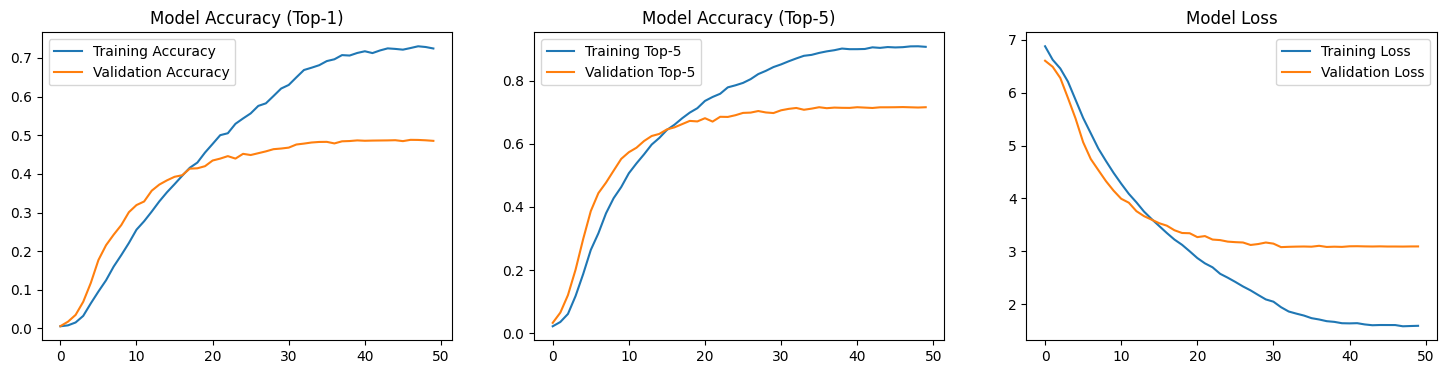

In [ ]:
import os
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.regularizers import l2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, GlobalAveragePooling2D, BatchNormalization  # ← added 
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau  # ← added
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.models import Model  # ← added
from PIL import Image

train_dir = "/home/berfin/Documents/newforbirds/spectrograms"

# ↓ ImageDataGenerator split into two parts: train, validation 
train_datagen = ImageDataGenerator(
    width_shift_range=0.1,
    height_shift_range=0.05,
    zoom_range=0.1,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    validation_split=0.2
)
val_datagen = ImageDataGenerator(
    validation_split=0.2
)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=(160, 160),
    batch_size=64,
    class_mode="categorical",
    subset="training"
)


val_gen = val_datagen.flow_from_directory(
    train_dir,
    target_size=(160, 160),
    batch_size=64,
    class_mode="categorical",
    subset="validation"
)

# Sequential CNN → EfficientNet transfer learning
base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(160, 160, 3)
)
from tensorflow.keras.regularizers import l2

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dense(512, activation='relu', kernel_regularizer=l2(0.001))(x)
x = Dropout(0.4)(x)
x = Dense(256, activation='relu', kernel_regularizer=l2(0.001))(x)
x = Dropout(0.3)(x)
output = Dense(train_gen.num_classes, activation='softmax')(x)
model = Model(inputs=base_model.input, outputs=output)
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.TopKCategoricalAccuracy(k=5, name='top5_accuracy')] 
)


from tensorflow.keras.callbacks import ModelCheckpoint

callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=7, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
    ModelCheckpoint(
        filepath='best_model.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(train_gen.num_classes),
    y=train_gen.classes
)
class_weight_dict = dict(enumerate(class_weights))
print("Class weights computed:", class_weight_dict)

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=50,
    callbacks=callbacks,
    class_weight=class_weight_dict
)

model.save("bird_cnn_model.keras")
print("Model saved as 'bird_cnn_model.keras'")


model = load_model("bird_cnn_model.keras")

plt.figure(figsize=(18, 4))
plt.subplot(1, 3, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy (Top-1)')
plt.legend()
plt.subplot(1, 3, 2)
plt.plot(history.history['top5_accuracy'], label='Training Top-5')
plt.plot(history.history['val_top5_accuracy'], label='Validation Top-5')
plt.title('Model Accuracy (Top-5)')
plt.legend()
plt.subplot(1, 3, 3)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.legend()
plt.show()

In [ ]:
from tensorflow.keras.models import load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import tensorflow as tf



tf.keras.backend.clear_session()


gpus = tf.config.list_physical_devices('GPU')
if gpus:
    tf.config.experimental.set_memory_growth(gpus[0], True)

# Upload model 
model = load_model('best_model.keras')
base_model = model.layers[1]  # EfficientNetB0

train_dir = "/home/berfin/Documents/newforbirds/spectrograms"

train_datagen = ImageDataGenerator(
    width_shift_range=0.1,
    height_shift_range=0.05,
    zoom_range=0.1,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    validation_split=0.2
)
val_datagen = ImageDataGenerator(validation_split=0.2)

train_gen = train_datagen.flow_from_directory(
    train_dir, target_size=(160, 160), batch_size=16,
    class_mode='categorical', subset='training'
)
val_gen = val_datagen.flow_from_directory(
    train_dir, target_size=(160, 160), batch_size=16,
    class_mode='categorical', subset='validation'
)

# 6. Class weights
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(train_gen.num_classes),
    y=train_gen.classes
)
class_weight_dict = dict(enumerate(class_weights))

# Fine-tuning — unfreeze the last 30 layers
for layer in model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
    elif layer.name in [l.name for l in model.layers[-30:]]:
        layer.trainable = True
    else:
        layer.trainable = False

# Fit
history_fine = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=50,
    callbacks=[
        EarlyStopping(monitor='val_accuracy', patience=7, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7),
        ModelCheckpoint('best_model_finetuned.keras', monitor='val_accuracy', save_best_only=True, verbose=1)
    ],
    class_weight=class_weight_dict
)

print(f"\nTop-1 val accuracy: {max(history_fine.history['val_accuracy']):.3f}")
print(f"Top-5 val accuracy: {max(history_fine.history['val_top5_accuracy']):.3f}")



Found 17149 images belonging to 264 classes.
Found 4225 images belonging to 264 classes.
Epoch 1/50


/home/berfin/anaconda3/lib/python3.11/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


 297/1072 ━━━━━━━━━━━━━━━━━━━━ 3:50 297ms/step - accuracy: 0.0165 - loss: 13.8377 - top5_accuracy: 0.0606

KeyboardInterrupt: 

NameError: name 'history_fine' is not defined

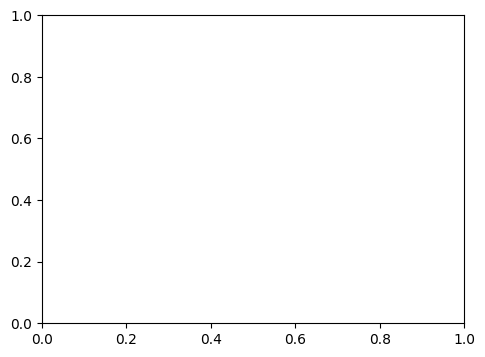

In [ ]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_fine.history['accuracy'], label='Training Accuracy')
plt.plot(history_fine.history['val_accuracy'], label='Validation Accuracy')
plt.title('Fine-tuning Accuracy')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history_fine.history['loss'], label='Training Loss')
plt.plot(history_fine.history['val_loss'], label='Validation Loss')
plt.title('Fine-tuning Loss')
plt.legend()
plt.show()

In [14]:
import os
species_dirs = os.listdir("/home/berfin/Documents/newforbirds/spectrograms")
counts = {s: len(os.listdir(f"/home/berfin/Documents/newforbirds/spectrograms/{s}")) 
          for s in species_dirs}
print(f"Total species: {len(counts)}")
print(f"Min examples: {min(counts.values())}")
print(f"Max examples: {max(counts.values())}")
print(f"Average examples: {sum(counts.values())/len(counts.values()):.1f}")
print(f"Total images: {sum(counts.values())}")

Total species: 264
Min examples: 9
Max examples: 100
Average examples: 81.0
Total images: 21374


# Wavelet (CWT) Pipeline — Mel-Spectrogram ile Karşılaştırma

Bu bölüm, yukarıdaki mel-spectrogram pipeline'ı ile **aynı şema, aynı batch size, aynı EfficientNetB0 mimarisi** kullanılarak hazırlanmıştır. Tek fark giriş temsilidir: ses sinyalleri mel-spectrogram yerine **Continuous Wavelet Transform (CWT) scalogram** olarak görüntüye çevrilmiştir (Morlet wavelet).

Amaç: STFT/mel tabanlı model ile wavelet tabanlı modelin accuracy üzerinden adil bir şekilde karşılaştırılması. Bu yüzden:
- Aynı ses klasörü (`audioset`) kullanılır
- Aynı `sr=16000`, `max_duration=5`, çıktı boyutu (`figsize=(2.24,2.24)`, `dpi=100`) korunur
- Aynı `target_size=(160,160)`, aynı `batch_size` (Phase 1: 64, Phase 2: 16), aynı augmentation, aynı callback'ler, aynı EfficientNetB0 mimarisi kullanılır
- Phase 1 (frozen base) ve Phase 2 (fine-tuning) ayrımı da mel-spectrogram modeliyle birebir aynıdır

**Not:** Eğer zaman yetmezse, Phase 2 (fine-tuning) atlanabilir — Phase 1 sonuçları (frozen-base transfer learning) tek başına da geçerli ve karşılaştırılabilir bir sonuçtur. Önemli olan, iki temsilin **aynı phase'de** karşılaştırılmasıdır (örn. ikisi de sadece Phase 1, veya ikisi de Phase 1+2).


In [ ]:
%pip install PyWavelets

import os
import numpy as np
import pywt
import matplotlib.pyplot as plt
import psutil
import time
import gc
import librosa  # used only for audio loading (librosa.load), not for mel features

# Configuration — mirrors the mel-spectrogram cell exactly, except the transform itself
audio_dir = '/home/berfin/Documents/newforbirds/audioset'
output_dir = '/home/berfin/Documents/newforbirds/spectrograms_wavelet'
processed_log = '/home/berfin/Documents/newforbirds/processed_files_wavelet.txt'
batch_size = 50
sr = 16000
max_duration = 5
n_scales = 128       # equivalent to n_mels=128, for a same-sized image
fmin = 50            # lower bound of the frequency range covered by the scales
fmax = 8000          # same fmax as the mel-spectrogram pipeline
wavelet_name = 'cmor1.5-1.0'  # complex Morlet wavelet (bandwidth=1.5, center freq=1.0)

# Create output directory if it doesn't exist
os.makedirs(output_dir, exist_ok=True)

# Load processed files log (if exists)
if os.path.exists(processed_log):
    with open(processed_log, 'r') as f:
        processed_files = set(line.strip() for line in f if line.strip())
else:
    processed_files = set()

# Find audio files
all_files = []
for root, dirs, files in os.walk(audio_dir):
    for file in files:
        if file.lower().endswith(('.mp3', '.wav')):
            full_path = os.path.join(root, file)
            if full_path not in processed_files:
                all_files.append(full_path)

print(f"Total remaining files to process: {len(all_files)}")

# Pre-compute the CWT scales once (frequency range fmin-fmax, log-spaced like mel filters)
f_c = pywt.central_frequency(wavelet_name)
scale_min = f_c * sr / fmax
scale_max = f_c * sr / fmin
scales = np.geomspace(scale_min, scale_max, num=n_scales)

# Target number of time frames, matched to what librosa.feature.melspectrogram would produce
# for the same sr/duration (hop_length=512 default): frames = floor(n_samples / hop_length) + 1
hop_length = 512
target_frames = int(sr * max_duration / hop_length) + 1

success_count = 0

# PROCESS FILES IN BATCHES
for i in range(0, len(all_files), batch_size):
    batch = all_files[i:i + batch_size]
    print(f"\nProcessing batch {i//batch_size + 1}/{(len(all_files) - 1)//batch_size + 1}")

    for file_path in batch:
        cpu_percent = psutil.cpu_percent(interval=0.1)
        mem_percent = psutil.virtual_memory().percent
        if cpu_percent > 85 or mem_percent > 85:
            print(f"High usage (CPU: {cpu_percent}%, MEM: {mem_percent}%) → Cooling down 15s")
            time.sleep(15)

        filename = os.path.basename(file_path)
        species_name = os.path.basename(os.path.dirname(file_path))

        species_dir = os.path.join(output_dir, species_name)
        os.makedirs(species_dir, exist_ok=True)

        print(f"Processing: {filename} (Species: {species_name})")

        try:
            y, sr_loaded = librosa.load(file_path, sr=sr, duration=max_duration)
        except Exception as e:
            print(f"Error loading {filename}: {e}")
            continue

        if len(y) == 0 or np.max(np.abs(y)) < 1e-10:
            print(f"Skipping {filename}: silent or empty")
            continue

        try:
            coef, _ = pywt.cwt(y, scales, wavelet_name, sampling_period=1/sr_loaded, method='fft')
        except Exception as e:
            print(f"Error computing CWT for {filename}: {e}")
            continue

        power = np.abs(coef) ** 2
        if np.max(power) == 0:
            print(f"Skipping {filename}: empty scalogram")
            continue

        # Downsample time axis to match the mel-spectrogram frame count (visual size parity)
        n_time = power.shape[1]
        indices = np.linspace(0, n_time - 1, target_frames).astype(int)
        power_ds = power[:, indices]

        # Convert to dB scale, normalized to max — same convention as librosa.power_to_db(ref=np.max)
        power_dB = 10 * np.log10(np.maximum(power_ds, 1e-10))
        power_dB = power_dB - power_dB.max()

        # Create figure exactly like the mel-spectrogram cell (same size, same dpi, no axes)
        fig, ax = plt.subplots(figsize=(2.24, 2.24), dpi=100)
        ax.set_axis_off()
        ax.imshow(power_dB, aspect='auto', origin='lower', cmap='magma', vmin=-80, vmax=0)

        output_file = os.path.join(species_dir, f'{os.path.splitext(filename)[0]}.png')
        try:
            fig.savefig(output_file, bbox_inches='tight', pad_inches=0)
            success_count += 1
            with open(processed_log, 'a') as logf:
                logf.write(file_path + '\n')
        except Exception as e:
            print(f"Error saving {output_file}: {e}")

        plt.close(fig)
        gc.collect()

    print(f"Batch {i//batch_size + 1} complete → Cooling down 5s")
    time.sleep(5)

print(f"\nProcessing complete. Saved {success_count} wavelet scalograms.")


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.regularizers import l2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, GlobalAveragePooling2D, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.models import Model
from PIL import Image

train_dir_wavelet = "/home/berfin/Documents/newforbirds/spectrograms_wavelet"

# Same augmentation scheme as the mel-spectrogram model
train_datagen_wv = ImageDataGenerator(
    width_shift_range=0.1,
    height_shift_range=0.05,
    zoom_range=0.1,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    validation_split=0.2
)
val_datagen_wv = ImageDataGenerator(
    validation_split=0.2
)

train_gen_wv = train_datagen_wv.flow_from_directory(
    train_dir_wavelet,
    target_size=(160, 160),
    batch_size=64,
    class_mode="categorical",
    subset="training"
)

val_gen_wv = val_datagen_wv.flow_from_directory(
    train_dir_wavelet,
    target_size=(160, 160),
    batch_size=64,
    class_mode="categorical",
    subset="validation"
)

# Same architecture: EfficientNetB0 transfer learning
base_model_wv = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(160, 160, 3)
)

base_model_wv.trainable = False  # Phase 1: freeze base — same as mel pipeline
x = base_model_wv.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dense(512, activation='relu', kernel_regularizer=l2(0.001))(x)
x = Dropout(0.4)(x)
x = Dense(256, activation='relu', kernel_regularizer=l2(0.001))(x)
x = Dropout(0.3)(x)
output_wv = Dense(train_gen_wv.num_classes, activation='softmax')(x)
model_wavelet = Model(inputs=base_model_wv.input, outputs=output_wv)
model_wavelet.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.TopKCategoricalAccuracy(k=5, name='top5_accuracy')]
)

callbacks_wv = [
    EarlyStopping(monitor='val_accuracy', patience=7, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
    ModelCheckpoint(
        filepath='best_model_wavelet.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

from sklearn.utils.class_weight import compute_class_weight

class_weights_wv = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(train_gen_wv.num_classes),
    y=train_gen_wv.classes
)
class_weight_dict_wv = dict(enumerate(class_weights_wv))
print("Class weights computed:", class_weight_dict_wv)

history_wavelet = model_wavelet.fit(
    train_gen_wv,
    validation_data=val_gen_wv,
    epochs=50,
    callbacks=callbacks_wv,
    class_weight=class_weight_dict_wv
)

model_wavelet.save("bird_cnn_model_wavelet.keras")
print("Model saved as 'bird_cnn_model_wavelet.keras'")

model_wavelet = load_model("bird_cnn_model_wavelet.keras")

plt.figure(figsize=(18, 4))
plt.subplot(1, 3, 1)
plt.plot(history_wavelet.history['accuracy'], label='Training Accuracy')
plt.plot(history_wavelet.history['val_accuracy'], label='Validation Accuracy')
plt.title('Wavelet Model Accuracy (Top-1)')
plt.legend()
plt.subplot(1, 3, 2)
plt.plot(history_wavelet.history['top5_accuracy'], label='Training Top-5')
plt.plot(history_wavelet.history['val_top5_accuracy'], label='Validation Top-5')
plt.title('Wavelet Model Accuracy (Top-5)')
plt.legend()
plt.subplot(1, 3, 3)
plt.plot(history_wavelet.history['loss'], label='Training Loss')
plt.plot(history_wavelet.history['val_loss'], label='Validation Loss')
plt.title('Wavelet Model Loss')
plt.legend()
plt.show()


In [ ]:
from tensorflow.keras.models import load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import tensorflow as tf

tf.keras.backend.clear_session()

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    tf.config.experimental.set_memory_growth(gpus[0], True)

# Upload model
model_wavelet = load_model('best_model_wavelet.keras')
base_model_wv = model_wavelet.layers[1]  # EfficientNetB0

train_dir_wavelet = "/home/berfin/Documents/newforbirds/spectrograms_wavelet"

train_datagen_wv = ImageDataGenerator(
    width_shift_range=0.1,
    height_shift_range=0.05,
    zoom_range=0.1,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    validation_split=0.2
)
val_datagen_wv = ImageDataGenerator(validation_split=0.2)

train_gen_wv = train_datagen_wv.flow_from_directory(
    train_dir_wavelet, target_size=(160, 160), batch_size=16,
    class_mode='categorical', subset='training'
)
val_gen_wv = val_datagen_wv.flow_from_directory(
    train_dir_wavelet, target_size=(160, 160), batch_size=16,
    class_mode='categorical', subset='validation'
)

# Class weights
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights_wv = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(train_gen_wv.num_classes),
    y=train_gen_wv.classes
)
class_weight_dict_wv = dict(enumerate(class_weights_wv))

# Fine-tuning — unfreeze the last 30 layers (same as the mel-spectrogram model)
for layer in model_wavelet.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
    elif layer.name in [l.name for l in model_wavelet.layers[-30:]]:
        layer.trainable = True
    else:
        layer.trainable = False

# Fit
history_fine_wavelet = model_wavelet.fit(
    train_gen_wv,
    validation_data=val_gen_wv,
    epochs=50,
    callbacks=[
        EarlyStopping(monitor='val_accuracy', patience=7, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7),
        ModelCheckpoint('best_model_wavelet_finetuned.keras', monitor='val_accuracy', save_best_only=True, verbose=1)
    ],
    class_weight=class_weight_dict_wv
)

print(f"\nTop-1 val accuracy: {max(history_fine_wavelet.history['val_accuracy']):.3f}")
print(f"Top-5 val accuracy: {max(history_fine_wavelet.history['val_top5_accuracy']):.3f}")


In [ ]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_fine_wavelet.history['accuracy'], label='Training Accuracy')
plt.plot(history_fine_wavelet.history['val_accuracy'], label='Validation Accuracy')
plt.title('Wavelet Model Fine-tuning Accuracy')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history_fine_wavelet.history['loss'], label='Training Loss')
plt.plot(history_fine_wavelet.history['val_loss'], label='Validation Loss')
plt.title('Wavelet Model Fine-tuning Loss')
plt.legend()
plt.show()


## Sonuç Karşılaştırması

In [ ]:
# Karşılaştırma: Mel-Spectrogram (STFT/Mel) vs Wavelet (CWT) Modeli
#
# Bu hücre, her iki modelin de eğitildiği aşamaya (Phase 1 ve/veya Phase 2) bağlı olarak
# mevcut olan accuracy değerlerini toplar ve yan yana karşılaştırır.
# Phase 2 (fine-tuning) çalıştırılmadıysa, ilgili satırlar otomatik olarak atlanır —
# bu durumda karşılaştırma sadece Phase 1 üzerinden yapılır, ki bu da geçerli bir kıyaslamadır.

results = {}

# Mel-spectrogram model — Phase 1
if 'history' in dir():
    results['Mel-Spectrogram (Phase 1)'] = {
        'val_accuracy': max(history.history['val_accuracy']),
        'val_top5_accuracy': max(history.history.get('val_top5_accuracy', [float('nan')]))
    }

# Mel-spectrogram model — Phase 2 (fine-tuned)
if 'history_fine' in dir():
    results['Mel-Spectrogram (Phase 2 - Fine-tuned)'] = {
        'val_accuracy': max(history_fine.history['val_accuracy']),
        'val_top5_accuracy': max(history_fine.history.get('val_top5_accuracy', [float('nan')]))
    }

# Wavelet model — Phase 1
if 'history_wavelet' in dir():
    results['Wavelet (Phase 1)'] = {
        'val_accuracy': max(history_wavelet.history['val_accuracy']),
        'val_top5_accuracy': max(history_wavelet.history.get('val_top5_accuracy', [float('nan')]))
    }

# Wavelet model — Phase 2 (fine-tuned)
if 'history_fine_wavelet' in dir():
    results['Wavelet (Phase 2 - Fine-tuned)'] = {
        'val_accuracy': max(history_fine_wavelet.history['val_accuracy']),
        'val_top5_accuracy': max(history_fine_wavelet.history.get('val_top5_accuracy', [float('nan')]))
    }

print(f"{'Model':<40}{'Val Top-1 Acc':<18}{'Val Top-5 Acc':<18}")
print("-" * 76)
for name, metrics in results.items():
    print(f"{name:<40}{metrics['val_accuracy']:<18.4f}{metrics['val_top5_accuracy']:<18.4f}")

# Görsel karşılaştırma (bar chart)
if results:
    labels = list(results.keys())
    top1_vals = [results[k]['val_accuracy'] for k in labels]

    plt.figure(figsize=(10, 5))
    bars = plt.bar(labels, top1_vals, color=['#4C72B0', '#4C72B0', '#DD8452', '#DD8452'][:len(labels)])
    plt.ylabel('Validation Top-1 Accuracy')
    plt.title('Mel-Spectrogram vs Wavelet (CWT) — Accuracy Karşılaştırması')
    plt.xticks(rotation=20, ha='right')
    plt.ylim(0, 1)
    for bar, val in zip(bars, top1_vals):
        plt.text(bar.get_x() + bar.get_width()/2, val + 0.02, f'{val:.3f}', ha='center')
    plt.tight_layout()
    plt.show()
else:
    print("Henüz hiçbir model eğitilmemiş — karşılaştırma için en az bir model history'si gerekli.")
